# Pengembangan dan Evaluasi Keandalan Model Deteksi Ulasan Produk Hasil Generatif Kecerdasan Buatan Berbasis MLP dan Fitur Stilometrik

**UTS Pembelajaran Mendalam** · Kelompok **CILUKBA** (IFC-Sore) · Program Studi S-1 Teknik Informatika, Universitas Mikroskil · Dosen: Nurhayati, S.Kom., M.Kom.

| NIM | Nama |
|---|---|
| 231110729 | Delvin Ayers |
| 231111441 | Osfredo Vent Kholish |
| 231110743 | Thienry |
| 231111101 | Andrian Cheniago |

Notebook ini memuat seluruh alur eksperimen: modul fitur stilometrik, pemuatan *dataset* Modern Fake Reviews, pembersihan, EDA, pemilihan fitur, pelatihan MLP (DNN) pada lima skenario dengan tiga *random seed* (1998, 7, 42), penetapan *threshold* berbasis FPR, uji McNemar *mid-p*, serta analisis keandalan pada model AI yang tidak dipakai saat pelatihan (GLM-5.2 dan LFM2.5-1.2B).

**Daftar isi:** 1 Lingkungan · 2 Modul · 3 Uji modul fitur · 4 Data · 5 Pembersihan · 6 Ekstraksi fitur · 7 EDA · 8 Pemilihan fitur · 9 Penelusuran pasangan ulasan · 10 Penalaan arsitektur · 11 Pelatihan skenario · 12 Evaluasi · 13 Grafik · 14 Bukti fitur unik · 15 Penyimpanan hasil · 16 Kompresi TFLite · 17 Artefak aplikasi website · 18 Uji aplikasi

## 1. Persiapan lingkungan
Seluruh *random seed* dikunci, dan versi pustaka dicetak agar eksperimen dapat direproduksi.

In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import tensorflow as tf

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
SRC_DIR = ROOT / "src"
FIG_DIR = ROOT / "figures"
OUT_DIR = ROOT / "outputs"
MODEL_DIR = ROOT / "models"
for folder in (DATA_DIR, SRC_DIR, FIG_DIR, OUT_DIR, MODEL_DIR):
    folder.mkdir(exist_ok=True)

SEEDS: list[int] = [1998, 7, 42]   # sama dengan seed eksperimen pembuat dataset
DPI: int = 300
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 11, "savefig.dpi": DPI, "figure.dpi": 100})

VERSIONS = {"python": platform.python_version(), "tensorflow": tf.__version__,
            "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
print(VERSIONS)
print("GPU:", tf.config.list_physical_devices("GPU") or "tidak ada (CPU)")

I0000 00:00:1793886304.197477     772 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793886304.198285     772 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


{'python': '3.13.18', 'tensorflow': '2.21.0', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
GPU: tidak ada (CPU)


I0000 00:00:1793886305.232845     772 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793886305.233367     772 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1793886305.418183     772 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Modul program
Setiap modul ditulis ke folder `src/` dengan `%%writefile` lalu diimpor. Modul yang sama dipakai ulang oleh aplikasi web pada UTS, sehingga tidak ada perbedaan *preprocessing* antara pelatihan dan inferensi.

In [2]:
%%writefile src/stylometry.py
"""Ekstraksi 11 fitur stilometrik untuk deteksi ulasan produk hasil generatif AI.

Definisi fitur mengikuti subbab 2.9 skripsi kelompok CILUKBA:
kata = deretan huruf yang boleh memuat satu apostrof di tengahnya,
kalimat = potongan teks yang dipisahkan tanda titik, seru, tanya, atau elipsis
(deretan tanda berurutan dihitung satu pemisah).
Modul ini dipakai SAMA PERSIS saat pelatihan dan saat inferensi (aplikasi web).
"""
from __future__ import annotations

import re
from typing import Dict, List

FEATURE_NAMES: List[str] = [
    "mattr", "avg_word_len", "function_word_ratio", "avg_sentence_len",
    "comma_ratio", "exclamation_ratio", "apostrophe_ratio",
    "informal_punct_ratio", "uppercase_ratio", "digit_ratio",
    "lowercase_start_ratio",
]
MATTR_WINDOW: int = 25
APOSTROPHES: tuple = ("'", "’")
WORD_RE = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)?")
SENT_SPLIT_RE = re.compile(r"(?:[.!?]|…)+")
INFORMAL_RE = re.compile(r"\.{3,}|…|!{2,}|\?{2,}")

FUNCTION_WORDS = set([
    'a', 'an', 'the', 'this', 'that', 'these', 'those', 'each', 'every', 'either',
    'neither', 'some', 'any', 'no', 'all', 'both', 'few', 'many', 'much', 'more',
    'most', 'several', 'such', 'another', 'other', 'i', 'me', 'my', 'mine', 'myself',
    'you', 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself',
    'she', 'her', 'hers', 'herself', 'it', 'its', 'itself', 'we', 'us', 'our', 'ours',
    'ourselves', 'they', 'them', 'their', 'theirs', 'themselves', 'who', 'whom',
    'whose', 'which', 'what', 'someone', 'something', 'anyone', 'anything', 'everyone',
    'everything', 'nobody', 'nothing', "i'm", "i've", "i'll", "i'd", "you're",
    "you've", "you'll", "you'd", "he's", "he'll", "he'd", "she's", "she'll", "she'd",
    "it's", "it'll", "we're", "we've", "we'll", "we'd", "they're", "they've",
    "they'll", "they'd", "that's", "there's", "what's", "who's", "let's", "isn't",
    "aren't", "wasn't", "weren't", "don't", "doesn't", "didn't", "haven't", "hasn't",
    "hadn't", "won't", "wouldn't", "can't", "couldn't", "shouldn't", "mustn't",
    'about', 'above', 'across', 'after', 'against', 'along', 'among', 'around', 'as',
    'at', 'before', 'behind', 'below', 'beneath', 'beside', 'between', 'beyond', 'by',
    'despite', 'down', 'during', 'for', 'from', 'in', 'inside', 'into', 'like', 'near',
    'of', 'off', 'on', 'onto', 'out', 'outside', 'over', 'past', 'since', 'through',
    'throughout', 'till', 'to', 'toward', 'towards', 'under', 'until', 'up', 'upon',
    'with', 'within', 'without', 'and', 'but', 'or', 'nor', 'so', 'yet', 'because',
    'although', 'though', 'while', 'whereas', 'if', 'unless', 'whether', 'than',
    'once', 'when', 'whenever', 'where', 'wherever', 'am', 'is', 'are', 'was', 'were',
    'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'can',
    'could', 'will', 'would', 'shall', 'should', 'may', 'might', 'must',])


def clean_text(text: str | None) -> str:
    """Normalisasi spasi: hapus spasi di tepi dan ringkas spasi berulang."""
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


def tokenize_words(text: str) -> List[str]:
    """Kembalikan daftar kata (huruf, boleh satu apostrof di tengah)."""
    return WORD_RE.findall(text)


def count_words(text: str) -> int:
    """Hitung jumlah kata dengan definisi yang sama dengan fitur."""
    return len(tokenize_words(text))


def split_sentences(text: str) -> List[str]:
    """Pecah teks menjadi kalimat; potongan tanpa huruf/angka diabaikan."""
    parts = SENT_SPLIT_RE.split(text)
    return [p.strip() for p in parts if re.search(r"[^\W_]", p)]


def _normalize_apostrophe(word: str) -> str:
    return word.replace("’", "'")


def mattr(words_lower: List[str], window: int = MATTR_WINDOW) -> float:
    """Moving-average type-token ratio; memakai TTR biasa jika N < window."""
    n = len(words_lower)
    if n == 0:
        return 0.0
    if n < window:
        return len(set(words_lower)) / n
    ttr_values = [
        len(set(words_lower[i:i + window])) / window
        for i in range(n - window + 1)
    ]
    return sum(ttr_values) / len(ttr_values)


def extract_features(text: str | None) -> Dict[str, float]:
    """Hitung 11 fitur stilometrik untuk satu teks ulasan."""
    text = clean_text(text)
    words = tokenize_words(text)
    n_words = len(words)
    if n_words == 0:
        return {name: 0.0 for name in FEATURE_NAMES}

    words_lower = [_normalize_apostrophe(w).lower() for w in words]
    sentences = split_sentences(text)
    n_sent = max(len(sentences), 1)

    letters_in_words = sum(sum(ch.isalpha() for ch in w) for w in words)
    letters_all = [ch for ch in text if ch.isalpha()]
    n_letters = len(letters_all)
    n_upper = sum(ch.isupper() for ch in letters_all)
    non_space = [ch for ch in text if not ch.isspace()]
    n_non_space = len(non_space)
    n_digits = sum(ch.isdigit() for ch in non_space)

    lower_start = 0
    for sentence in sentences:
        first = next((ch for ch in sentence if ch.isalpha()), None)
        if first is not None and first.islower():
            lower_start += 1

    return {
        "mattr": mattr(words_lower),
        "avg_word_len": letters_in_words / n_words,
        "function_word_ratio": sum(w in FUNCTION_WORDS for w in words_lower) / n_words,
        "avg_sentence_len": n_words / n_sent,
        "comma_ratio": text.count(",") / n_words,
        "exclamation_ratio": text.count("!") / n_words,
        "apostrophe_ratio": sum(text.count(a) for a in APOSTROPHES) / n_words,
        "informal_punct_ratio": len(INFORMAL_RE.findall(text)) / n_words,
        "uppercase_ratio": n_upper / n_letters if n_letters else 0.0,
        "digit_ratio": n_digits / n_non_space if n_non_space else 0.0,
        "lowercase_start_ratio": lower_start / n_sent,
    }


Writing src/stylometry.py


In [3]:
%%writefile src/data.py
"""Pemuatan dataset Modern Fake Reviews, pembersihan, dan penelusuran src_idx."""
from __future__ import annotations

import re
import unicodedata
import urllib.request
from pathlib import Path
from typing import Dict, Tuple

import numpy as np
import pandas as pd

from stylometry import FEATURE_NAMES, clean_text, count_words, extract_features

SPLIT_SEED: int = 1998
HF_REPOS: Dict[str, str] = {
    "deepseek": "Flowerly/modern-fake-reviews",
    "glm": "Flowerly/modern-fake-reviews-glm",
    "lfm": "Flowerly/modern-fake-reviews-lfm",
}
GITHUB_RAW: str = "https://raw.githubusercontent.com/PurplexyFlower/Fake-review/main/dataset/"
GITHUB_FILES: Dict[str, str] = {
    "deepseek": "modern_reviews_deepseek.csv",
    "glm": "modern_reviews_glm.csv",
    "lfm": "modern_reviews_lfm.csv",
    "raw_deepseek": "sota_fakes_deepseek.csv",
    "original": "fake reviews dataset.csv",
}
LABEL_MAP: Dict[str, int] = {"OR": 0, "CG": 1}


def _download(name: str, data_dir: Path) -> Path:
    """Unduh berkas CSV pembuat dataset dari GitHub bila belum tersedia."""
    data_dir.mkdir(parents=True, exist_ok=True)
    path = data_dir / GITHUB_FILES[name]
    if not path.exists():
        url = GITHUB_RAW + urllib.request.quote(GITHUB_FILES[name])
        urllib.request.urlretrieve(url, path)
    return path


def load_official_splits(variant: str, data_dir: Path) -> Tuple[pd.DataFrame, ...]:
    """Muat pembagian resmi (train/validation/test) untuk satu varian dataset.

    Urutan sumber: (1) Hugging Face Hub; (2) bila Hub tidak dapat diakses,
    CSV resmi di GitHub pembuat dataset dibagi ulang dengan prosedur yang
    didokumentasikan pembuatnya: train_test_split(test_size=0.2, seed=1998),
    lalu sisa 20% dibagi dengan test_size=0.7, seed=1998.
    """
    from datasets import Dataset, load_dataset

    try:
        hub = load_dataset(HF_REPOS[variant])
        frames = [hub[s].to_pandas() for s in ("train", "validation", "test")]
        source = "Hugging Face Hub"
    except Exception:  # noqa: BLE001 - jaringan dapat diblokir
        full = pd.read_csv(_download(variant, data_dir))
        first = Dataset.from_pandas(full, preserve_index=False).train_test_split(
            test_size=0.2, seed=SPLIT_SEED)
        second = first["test"].train_test_split(test_size=0.7, seed=SPLIT_SEED)
        frames = [first["train"].to_pandas(), second["train"].to_pandas(),
                  second["test"].to_pandas()]
        source = "GitHub (split ulang seed 1998)"
    for frame in frames:
        frame["y"] = frame["label"].map(LABEL_MAP).astype(int)
    print(f"[{variant}] sumber data: {source}; ukuran: {[len(f) for f in frames]}")
    return tuple(frames)


def clean_splits(train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame
                 ) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Pembersihan minimal tanpa mengubah huruf kapital dan tanda baca.

    Langkah: normalisasi spasi, keluarkan teks kosong, keluarkan duplikat persis
    di data training, keluarkan teks training yang sama dengan validation/test.
    Data validation dan testing resmi tidak dikurangi.
    """
    report = {}
    frames = {"train": train.copy(), "val": val.copy(), "test": test.copy()}
    for name, frame in frames.items():
        frame["text_"] = frame["text_"].map(clean_text)
        report[(name, "empty")] = int((frame["text_"] == "").sum())
        report[(name, "dup_within")] = int(frame["text_"].duplicated().sum())
        report[(name, "conflict_label")] = int(
            frame.groupby("text_")["y"].nunique().gt(1).sum())
        frames[name] = frame[frame["text_"] != ""]
    tr = frames["train"]
    tr = tr[~tr["text_"].duplicated()]
    held = set(frames["val"]["text_"]) | set(frames["test"]["text_"])
    report[("train", "overlap_val_test")] = int(tr["text_"].isin(held).sum())
    tr = tr[~tr["text_"].isin(held)]
    report[("val", "overlap_test")] = int(
        frames["val"]["text_"].isin(set(frames["test"]["text_"])).sum())
    frames["train"] = tr
    rep = pd.Series(report).unstack()
    return frames["train"].reset_index(drop=True), frames["val"].reset_index(
        drop=True), frames["test"].reset_index(drop=True), rep


def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Tambahkan 11 kolom fitur stilometrik dan jumlah kata."""
    feats = pd.DataFrame([extract_features(t) for t in frame["text_"]])
    out = pd.concat([frame.reset_index(drop=True), feats], axis=1)
    out["n_words"] = out["text_"].map(count_words)
    out["rating"] = out["rating"].astype(float)
    return out


# ---- Penelusuran ulasan manusia sumber (src_idx) ---------------------------
_SMART = {0x2018: "'", 0x2019: "'", 0x201a: "'", 0x201b: "'", 0x201c: '"',
          0x201d: '"', 0x201e: '"', 0x2032: "'", 0x2033: '"', 0x2013: ", ",
          0x2014: ", ", 0x2026: "...", 0x00a0: " "}


def creator_normalize(text: str) -> str:
    """Replika fungsi normalize_text milik pembuat dataset (build_modern_dataset.py)."""
    text = str(text).translate(_SMART)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s*,\s*,", ", ", text)
    text = re.sub(r"\s+([,.!?;:])", r"\1", text)
    text = re.sub(r",(\s*[.!?])", r"\1", text)
    return text.strip().strip(",").strip()


def trace_sources(test: pd.DataFrame, train: pd.DataFrame, val: pd.DataFrame,
                  data_dir: Path) -> pd.DataFrame:
    """Temukan lokasi ulasan manusia sumber untuk setiap ulasan AI data testing."""
    raw = pd.read_csv(_download("raw_deepseek", data_dir))
    orig = pd.read_csv(_download("original", data_dir))
    raw["key"] = raw["text_"].map(creator_normalize).map(clean_text)
    gen_to_src = dict(zip(raw["key"], raw["src_idx"]))
    location = {}
    for name, frame in (("test", test), ("val", val), ("train", train)):
        for text in frame.loc[frame["y"] == 0, "text_"]:
            location[text] = name
    rows = []
    for _, row in test[test["y"] == 1].iterrows():
        src = gen_to_src.get(row["text_"])
        if src is None or pd.isna(src):
            rows.append({"text_": row["text_"], "src_idx": np.nan, "src_loc": "tidak ditemukan",
                         "same_cat_rating": np.nan})
            continue
        src_row = orig.iloc[int(src)]
        src_text = clean_text(creator_normalize(src_row["text_"]))
        rows.append({
            "text_": row["text_"], "src_idx": int(src),
            "src_loc": location.get(src_text, "tidak ada di dataset akhir"),
            "same_cat_rating": bool(src_row["category"] == row["category"]
                                    and float(src_row["rating"]) == float(row["rating"])),
        })
    return pd.DataFrame(rows)


Writing src/data.py


In [4]:
%%writefile src/selection.py
"""Pemilihan fitur stilometrik berbasis data training saja (subbab 2.10 skripsi)."""
from __future__ import annotations

from typing import Dict, List

import pandas as pd
from sklearn.metrics import roc_auc_score

CORR_LIMIT: float = 0.9          # |rho| > 0,9 dianggap mengukur hal yang sama
LENGTH_CORR_LIMIT: float = 0.9   # |rho| > 0,9 terhadap jumlah kata = proksi panjang
ARTIFACT_FEATURES: List[str] = []  # tanda pisah sudah tidak dijadikan fitur


def select_features(train: pd.DataFrame, candidates: List[str]) -> Dict[str, object]:
    """Terapkan empat kriteria pemilihan fitur dan kembalikan tabel keputusannya."""
    auroc = {f: roc_auc_score(train["y"], train[f]) for f in candidates}
    power = {f: abs(a - 0.5) for f, a in auroc.items()}
    rho = train[candidates + ["n_words"]].corr(method="spearman")
    decision = {f: "Dipertahankan" for f in candidates}
    for i, fa in enumerate(candidates):
        for fb in candidates[i + 1:]:
            if abs(rho.loc[fa, fb]) > CORR_LIMIT:
                weaker = fa if power[fa] < power[fb] else fb
                decision[weaker] = f"Dikeluarkan: |rho| > {CORR_LIMIT} dengan fitur lebih kuat"
    for f in candidates:
        if abs(rho.loc[f, "n_words"]) > LENGTH_CORR_LIMIT:
            decision[f] = "Dikeluarkan: bergantung pada panjang ulasan"
        if f in ARTIFACT_FEATURES:
            decision[f] = "Dikeluarkan: artefak pembuatan data"
    table = pd.DataFrame({
        "AUROC": pd.Series(auroc), "Daya pembeda": pd.Series(power),
        "rho_jumlah_kata": rho.loc[candidates, "n_words"], "Keputusan": pd.Series(decision),
    }).sort_values("Daya pembeda", ascending=False)
    selected = [f for f in candidates if decision[f] == "Dipertahankan"]
    pairs = [(fa, fb, abs(rho.loc[fa, fb])) for i, fa in enumerate(candidates)
             for fb in candidates[i + 1:]]
    max_pair = sorted(pairs, key=lambda item: item[2], reverse=True)[:3]
    return {"table": table, "selected": selected, "spearman": rho,
            "max_pair": max_pair}


Writing src/selection.py


In [5]:
%%writefile src/model.py
"""Arsitektur MLP (DNN) dan prosedur pelatihan dengan TensorFlow/Keras."""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Dict, List, Optional

import numpy as np
import tensorflow as tf
from sklearn.metrics import roc_auc_score

DROPOUT: float = 0.1
BATCH_SIZE: int = 32
MAX_EPOCHS: int = 20
PATIENCE: int = 3
WEIGHT_DECAY: float = 0.01


def set_global_seed(seed: int) -> None:
    """Kunci seluruh sumber keacakan (Python, NumPy, TensorFlow)."""
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()


def build_model(arch: str, x_train: np.ndarray, regularized: bool = True) -> tf.keras.Model:
    """Bangun MLP M1 (Dense 256) atau M2 (Dense 64 -> Dense 32).

    Layer Normalization di-adapt HANYA pada data training (z-score) dan ikut
    tersimpan di dalam model sehingga inferensi memakai statistik yang sama.
    """
    norm = tf.keras.layers.Normalization(axis=-1, name="zscore")
    norm.adapt(x_train.astype("float32"))
    inputs = tf.keras.Input(shape=(x_train.shape[1],), name="fitur")
    x = norm(inputs)
    if arch == "M1":
        x = tf.keras.layers.Dense(256, activation="relu", name="hidden_1")(x)
        if regularized:
            x = tf.keras.layers.Dropout(DROPOUT, name="dropout_1")(x)
    elif arch == "M2":
        for i, units in enumerate((64, 32), start=1):
            x = tf.keras.layers.Dense(units, name=f"hidden_{i}")(x)
            if regularized:
                x = tf.keras.layers.BatchNormalization(name=f"batchnorm_{i}")(x)
            x = tf.keras.layers.Activation("relu", name=f"relu_{i}")(x)
            if regularized:
                x = tf.keras.layers.Dropout(DROPOUT, name=f"dropout_{i}")(x)
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")
    outputs = tf.keras.layers.Dense(2, activation="softmax", name="output")(x)
    return tf.keras.Model(inputs, outputs, name=f"MLP_{arch}")


def make_dataset(x: np.ndarray, y: np.ndarray, seed: int, shuffle: bool) -> tf.data.Dataset:
    """Pipeline tf.data: from_tensor_slices -> shuffle -> batch -> prefetch."""
    ds = tf.data.Dataset.from_tensor_slices((x.astype("float32"), y.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


class AurocCheckpoint(tf.keras.callbacks.Callback):
    """Hitung AUROC data validation tiap epoch, simpan bobot terbaik, early stopping."""

    def __init__(self, x_val: np.ndarray, y_val: np.ndarray, patience: Optional[int]):
        super().__init__()
        self.x_val, self.y_val, self.patience = x_val, y_val, patience
        self.best, self.best_epoch, self.wait, self.best_weights = -np.inf, 0, 0, None

    def on_epoch_end(self, epoch: int, logs: Optional[Dict] = None) -> None:
        p = self.model.predict(self.x_val, verbose=0)[:, 1]
        auroc = float(roc_auc_score(self.y_val, p))
        logs = logs if logs is not None else {}
        logs["val_auroc"] = auroc
        if auroc > self.best:
            self.best, self.best_epoch, self.wait = auroc, epoch + 1, 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
            if self.patience is not None and self.wait >= self.patience:
                self.model.stop_training = True

    def on_train_end(self, logs: Optional[Dict] = None) -> None:
        if self.patience is not None and self.best_weights is not None:
            self.model.set_weights(self.best_weights)


@dataclass
class TrainResult:
    model: tf.keras.Model
    history: Dict[str, List[float]]
    best_epoch: int
    best_val_auroc: float
    epochs_run: int = field(default=0)


def train_model(arch: str, x_tr: np.ndarray, y_tr: np.ndarray, x_va: np.ndarray,
                y_va: np.ndarray, seed: int, lr: float = 1e-3,
                regularized: bool = True) -> TrainResult:
    """Latih satu model. regularized=False = skenario S3 (tanpa dropout/BN,
    SGD learning rate tetap 0,01, tanpa early stopping, 20 epoch)."""
    set_global_seed(seed)
    model = build_model(arch, x_tr, regularized=regularized)
    if regularized:
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=WEIGHT_DECAY)
        patience: Optional[int] = PATIENCE
    else:
        optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)
        patience = None
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    callback = AurocCheckpoint(x_va, y_va, patience)
    hist = model.fit(make_dataset(x_tr, y_tr, seed, True), epochs=MAX_EPOCHS,
                     validation_data=make_dataset(x_va, y_va, seed, False),
                     callbacks=[callback], verbose=0)
    return TrainResult(model, hist.history, callback.best_epoch, callback.best,
                       len(hist.history["loss"]))


Writing src/model.py


In [6]:
%%writefile src/evaluation.py
"""Metrik evaluasi, threshold berbasis FPR, dan uji McNemar mid-p."""
from __future__ import annotations

from typing import Dict

import numpy as np
from scipy.stats import binom
from sklearn.metrics import confusion_matrix, roc_auc_score

MAX_FPR: float = 0.01


def threshold_at_fpr(y_val: np.ndarray, p_val: np.ndarray, max_fpr: float = MAX_FPR) -> float:
    """t* = min{ t : FPR_val(t) <= max_fpr }, keputusan AI jika p >= t."""
    y_val, p_val = np.asarray(y_val), np.asarray(p_val)
    neg_scores = p_val[y_val == 0]
    allowed_fp = int(np.floor(max_fpr * len(neg_scores)))
    for t in np.unique(p_val):
        if (neg_scores >= t).sum() <= allowed_fp:
            return float(t)
    return float(np.nextafter(p_val.max(), np.inf))


def classification_metrics(y: np.ndarray, p: np.ndarray, t: float) -> Dict[str, float]:
    """Accuracy, precision, recall, F1-score, FPR, FNR, dan AUROC pada threshold t."""
    y = np.asarray(y)
    pred = (np.asarray(p) >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    out = {"TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
           "accuracy": (tp + tn) / len(y), "precision": precision, "recall": recall,
           "f1": f1, "fpr": fp / (fp + tn) if fp + tn else np.nan,
           "fnr": fn / (fn + tp) if fn + tp else np.nan}
    out["auroc"] = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
    return out


def mcnemar_midp(correct_a: np.ndarray, correct_b: np.ndarray) -> Dict[str, float]:
    """Uji McNemar mid-p. n01 = A salah & B benar; n10 = A benar & B salah."""
    a, b = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    n = n01 + n10
    if n == 0:
        p_value = 1.0
    else:
        m = min(n01, n10)
        p_value = float(2 * binom.cdf(m, n, 0.5) - binom.pmf(m, n, 0.5))
        p_value = min(max(p_value, 0.0), 1.0)
    return {"n01": n01, "n10": n10, "n": n, "p_mid": p_value}


Writing src/evaluation.py


In [7]:
%%writefile src/inference.py
"""Pemeriksaan masukan (fitur unik 2) dan prediksi satu teks."""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import List

from langdetect import DetectorFactory, detect_langs
from langdetect.lang_detect_exception import LangDetectException

from stylometry import clean_text, count_words

DetectorFactory.seed = 0  # hasil deteksi bahasa deterministik (NF3)


@dataclass
class InputCheck:
    status: str            # "ok", "kosong", atau "bukan_inggris"
    n_words: int
    warnings: List[str] = field(default_factory=list)
    message: str = ""


def detect_english(text: str) -> bool:
    """True bila bahasa dengan peluang terbesar menurut langdetect adalah Inggris."""
    try:
        return detect_langs(text)[0].lang == "en"
    except LangDetectException:
        return False


def check_input(text: str | None, q1: int, l_max: int) -> InputCheck:
    """Validasi teks: kosong ditolak, non-Inggris ditolak, panjang di luar
    kisaran (N <= Q1 atau N > L_maks) tetap diproses dengan peringatan."""
    text = clean_text(text)
    if text == "":
        return InputCheck("kosong", 0, message="Teks ulasan wajib diisi.")
    n = count_words(text)
    if n == 0 or not detect_english(text):
        return InputCheck("bukan_inggris", n,
                          message="Hanya teks ulasan berbahasa Inggris yang didukung.")
    warnings = []
    if n <= q1:
        warnings.append(f"Teks terlalu pendek ({n} kata, panjang yang disarankan "
                        f"{q1 + 1} sampai {l_max} kata). Hasil deteksi pada teks yang "
                        "sangat pendek kurang dapat diandalkan.")
    if n > l_max:
        warnings.append(f"Teks terlalu panjang ({n} kata, melebihi {l_max} kata). "
                        "Teks lebih panjang daripada ulasan AI yang dipakai saat pelatihan, "
                        "sehingga hasil deteksi kurang dapat diandalkan.")
    return InputCheck("ok", n, warnings)


Writing src/inference.py


In [8]:
sys.path.insert(0, str(SRC_DIR))
import importlib
import data as data_mod
import evaluation as ev
import inference as inf
import model as mdl
import selection as sel
import stylometry as sty
for module in (sty, data_mod, sel, mdl, ev, inf):
    importlib.reload(module)

## 3. Uji modul fitur terhadap hitungan manual
Contoh ulasan dari subbab 3.1.2 skripsi dihitung manual; nilai dari kode harus sama persis (4 desimal).

In [9]:
SAMPLE = ("i love this blender!! It's powerful, but the lid cracked after 2 weeks... "
          "Would I buy it again? Maybe.")
MANUAL = {"mattr": 17 / 18, "avg_word_len": 74 / 18, "function_word_ratio": 9 / 18,
          "avg_sentence_len": 18 / 4, "comma_ratio": 1 / 18, "exclamation_ratio": 2 / 18,
          "apostrophe_ratio": 1 / 18, "informal_punct_ratio": 2 / 18,
          "uppercase_ratio": 4 / 74, "digit_ratio": 1 / 84, "lowercase_start_ratio": 1 / 4}
code_values = sty.extract_features(SAMPLE)
unit_test = pd.DataFrame({"manual": MANUAL, "kode": code_values}).round(4)
unit_test["sama"] = unit_test["manual"] == unit_test["kode"]
assert unit_test["sama"].all(), "Modul fitur tidak sesuai hitungan manual"
mattr_text = ("The blender is strong and the blender is quiet, but the lid is weak and the lid "
              "cracked after two weeks of daily use at home now.")
mattr_value = sty.mattr([w.lower() for w in sty.tokenize_words(mattr_text)])
assert round(mattr_value, 2) == 0.72
unit_test

,manual,kode,sama
mattr,0.9444,0.9444,True
avg_word_len,4.1111,4.1111,True
function_word_ratio,0.5000,0.5000,True
avg_sentence_len,4.5000,4.5000,True
comma_ratio,0.0556,0.0556,True
exclamation_ratio,0.1111,0.1111,True
apostrophe_ratio,0.0556,0.0556,True
informal_punct_ratio,0.1111,0.1111,True
uppercase_ratio,0.0541,0.0541,True
digit_ratio,0.0119,0.0119,True


## 4. Memuat data
Data utama Modern Fake Reviews (DeepSeek-v4-pro) serta varian GLM-5.2 dan LFM2.5-1.2B dimuat dengan pembagian resmi. Bila Hugging Face Hub tidak dapat diakses, CSV resmi di GitHub pembuat dataset dibagi ulang dengan prosedur yang sama (seed 1998), dan hasilnya identik dengan ukuran pembagian resmi.

In [10]:
raw = {v: data_mod.load_official_splits(v, DATA_DIR) for v in ("deepseek", "glm", "lfm")}
train_raw, val_raw, test_raw = raw["deepseek"]
glm_test_ai = raw["glm"][2].query("y == 1").copy()
lfm_test_ai = raw["lfm"][2].query("y == 1").copy()
train_raw.head()

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[deepseek] sumber data: GitHub (split ulang seed 1998); ukuran: [32339, 2425, 5660]


[glm] sumber data: GitHub (split ulang seed 1998); ukuran: [32332, 2425, 5659]


[lfm] sumber data: GitHub (split ulang seed 1998); ukuran: [32339, 2425, 5660]


,category,rating,label,text_,y
0,Pet_Supplies_5,3.0,CG,"Maybe okay for a calm small dog, but not for m...",1
1,Pet_Supplies_5,5.0,CG,"Order arrived fast and in perfect condition, n...",1
2,Movies_and_TV_5,5.0,CG,Went in with sky-high hopes and it still blew ...,1
3,Clothing_Shoes_and_Jewelry_5,3.0,CG,"These pants fit my tall, lanky frame better th...",1
4,Clothing_Shoes_and_Jewelry_5,5.0,CG,I've had these for a few months now and honest...,1


## 5. Pembersihan data
Pembersihan dibuat minimal: huruf kapital, tanda baca, dan angka dipertahankan karena merupakan ciri gaya penulisan.

In [11]:
train_c, val_c, test_c, clean_report = data_mod.clean_splits(train_raw, val_raw, test_raw)
glm_test_ai["text_"] = glm_test_ai["text_"].map(sty.clean_text)
lfm_test_ai["text_"] = lfm_test_ai["text_"].map(sty.clean_text)
split_sizes = pd.DataFrame({
    "resmi": [len(train_raw), len(val_raw), len(test_raw)],
    "setelah_pembersihan": [len(train_c), len(val_c), len(test_c)],
    "OR": [int((d.y == 0).sum()) for d in (train_c, val_c, test_c)],
    "CG": [int((d.y == 1).sum()) for d in (train_c, val_c, test_c)]},
    index=["training", "validation", "testing"])
print(clean_report)
print("GLM CG:", len(glm_test_ai), " LFM CG:", len(lfm_test_ai))
split_sizes

       conflict_label  dup_within  empty  overlap_test  overlap_val_test
test              0.0         0.0    0.0           NaN               NaN
train             0.0         1.0    0.0           NaN               0.0
val               0.0         0.0    0.0           0.0               NaN
GLM CG: 2819  LFM CG: 2802


,resmi,setelah_pembersihan,OR,CG
training,32339,32338,16166,16172
validation,2425,2425,1187,1238
testing,5660,5660,2858,2802


## 6. Ekstraksi fitur stilometrik

In [12]:
t0 = time.time()
train = data_mod.add_features(train_c)
val = data_mod.add_features(val_c)
test = data_mod.add_features(test_c)
glm = data_mod.add_features(glm_test_ai)
lfm = data_mod.add_features(lfm_test_ai)
FEATS = sty.FEATURE_NAMES
print(f"Ekstraksi selesai dalam {time.time() - t0:.1f} detik")
train[FEATS + ["n_words", "rating"]].describe().T.round(4)

Ekstraksi selesai dalam 8.3 detik


,count,mean,std,min,25%,50%,75%,max
mattr,32338.0,0.9281,0.0518,0.3294,0.8968,0.9303,0.9600,1.0000
avg_word_len,32338.0,4.3249,0.4137,2.6667,4.0588,4.3188,4.5714,7.3000
function_word_ratio,32338.0,0.4636,0.0820,0.0000,0.4194,0.4691,0.5159,0.9167
avg_sentence_len,32338.0,13.9284,5.4485,2.0000,10.5000,13.3333,17.0000,198.0000
comma_ratio,32338.0,0.0421,0.0364,0.0000,0.0000,0.0417,0.0635,0.3636
exclamation_ratio,32338.0,0.0061,0.0285,0.0000,0.0000,0.0000,0.0000,1.2000
apostrophe_ratio,32338.0,0.0233,0.0270,0.0000,0.0000,0.0169,0.0397,0.4000
informal_punct_ratio,32338.0,0.0019,0.0111,0.0000,0.0000,0.0000,0.0000,0.3333
uppercase_ratio,32338.0,0.0305,0.0493,0.0000,0.0181,0.0235,0.0330,1.0000
digit_ratio,32338.0,0.0024,0.0074,0.0000,0.0000,0.0000,0.0000,0.1707


## 7. Exploratory Data Analysis (EDA)
Seluruh statistik dihitung dari data *training*, kecuali distribusi kelas yang menampilkan ketiga bagian data.

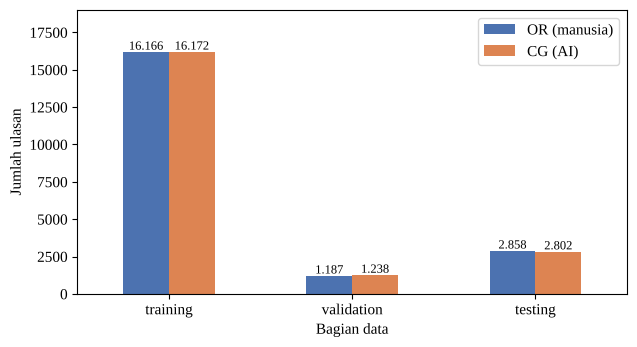

L_maks = 136  Q1/Q2/Q3 = 22 42 91


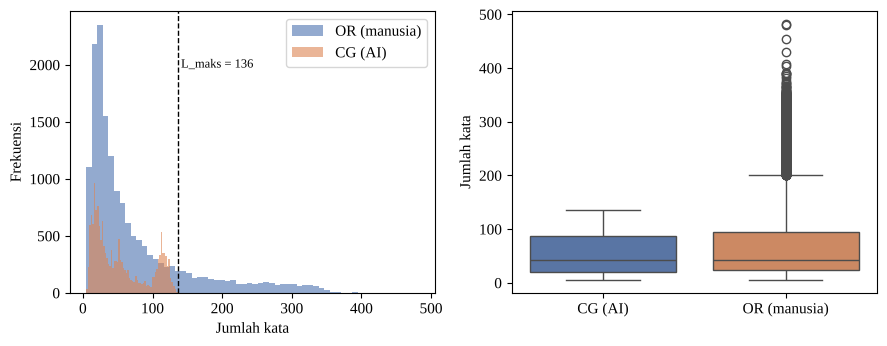

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
OR (manusia),16166.0,74.21,76.87,5.0,23.0,42.0,94.0,482.0
CG (AI),16172.0,54.05,38.45,5.0,21.0,42.0,88.0,136.0


In [13]:
LABELS = {0: "OR (manusia)", 1: "CG (AI)"}
COLORS = {0: "#4C72B0", 1: "#DD8452"}

# 7a. Distribusi kelas
fig, ax = plt.subplots(figsize=(6.5, 3.6))
split_sizes[["OR", "CG"]].plot.bar(ax=ax, color=[COLORS[0], COLORS[1]], rot=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v):,}".replace(",", ".") for v in container.datavalues], fontsize=9)
ax.set_ylabel("Jumlah ulasan"); ax.set_xlabel("Bagian data")
ax.legend(["OR (manusia)", "CG (AI)"]); ax.set_ylim(0, 19000)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_distribusi_kelas.png"); plt.show()

# 7b. Word count
wc_stats = train.groupby("y")["n_words"].describe().rename(index=LABELS)
L_MAX = int(train.loc[train.y == 1, "n_words"].max())
Q1, Q2, Q3 = (int(v) for v in train["n_words"].quantile([0.25, 0.5, 0.75]))
print("L_maks =", L_MAX, " Q1/Q2/Q3 =", Q1, Q2, Q3)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for y in (0, 1):
    axes[0].hist(train.loc[train.y == y, "n_words"], bins=60, alpha=0.6,
                 color=COLORS[y], label=LABELS[y])
axes[0].axvline(L_MAX, color="black", ls="--", lw=1)
axes[0].text(L_MAX + 5, axes[0].get_ylim()[1] * 0.8, f"L_maks = {L_MAX}", fontsize=9)
axes[0].set_xlabel("Jumlah kata"); axes[0].set_ylabel("Frekuensi"); axes[0].legend()
sns.boxplot(data=train.assign(Kelas=train.y.map(LABELS)), x="Kelas", y="n_words",
            hue="Kelas", palette=[COLORS[0], COLORS[1]], ax=axes[1], legend=False)
axes[1].set_ylabel("Jumlah kata"); axes[1].set_xlabel("")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_word_count.png"); plt.show()
wc_stats.round(2)

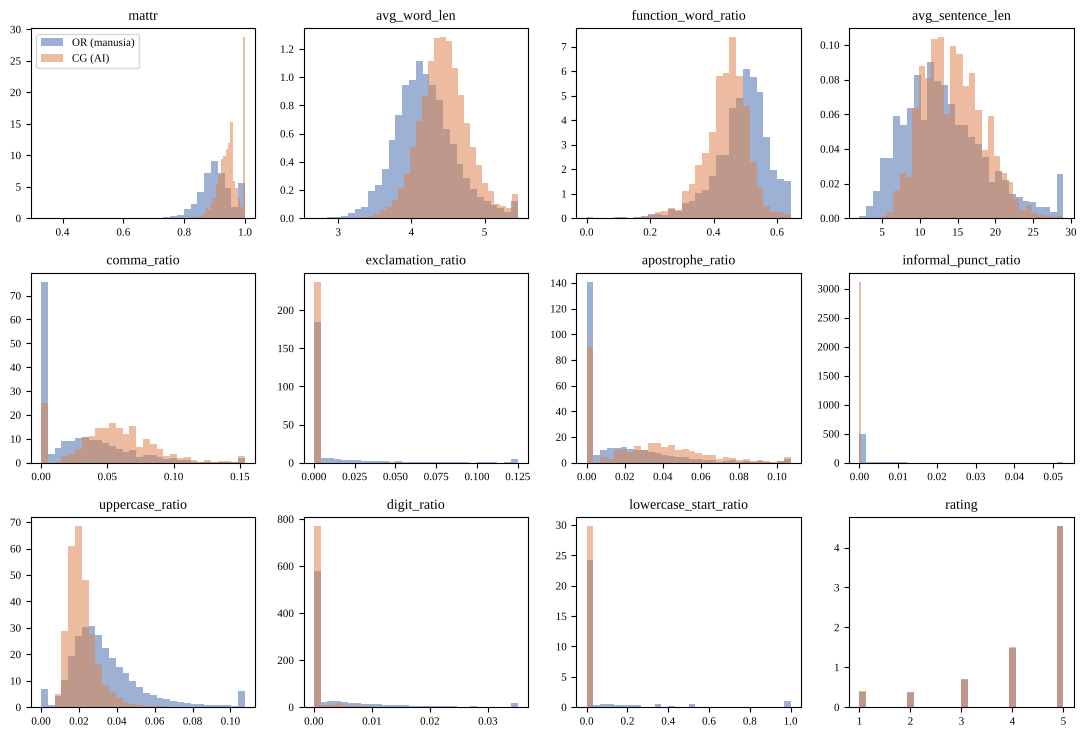

y,OR (manusia),CG (AI)
mattr,0.9052,0.9509
avg_word_len,4.1919,4.4578
function_word_ratio,0.4884,0.4388
avg_sentence_len,13.4668,14.3900
comma_ratio,0.0296,0.0545
exclamation_ratio,0.0117,0.0006
apostrophe_ratio,0.0167,0.0300
informal_punct_ratio,0.0038,0.0000
uppercase_ratio,0.0391,0.0218
digit_ratio,0.0040,0.0008


In [14]:
# 7c. Histogram fitur numerik per kelas
plot_feats = FEATS + ["rating"]
fig, axes = plt.subplots(3, 4, figsize=(11, 7.5))
for ax, f in zip(axes.ravel(), plot_feats):
    upper = train[f].quantile(0.99)
    for y in (0, 1):
        vals = train.loc[train.y == y, f].clip(upper=upper)
        ax.hist(vals, bins=30, alpha=0.55, color=COLORS[y], density=True, label=LABELS[y])
    ax.set_title(f, fontsize=10); ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_histogram_fitur.png"); plt.show()
feat_means = train.groupby("y")[plot_feats].mean().T.rename(columns=LABELS)
feat_means.round(4)

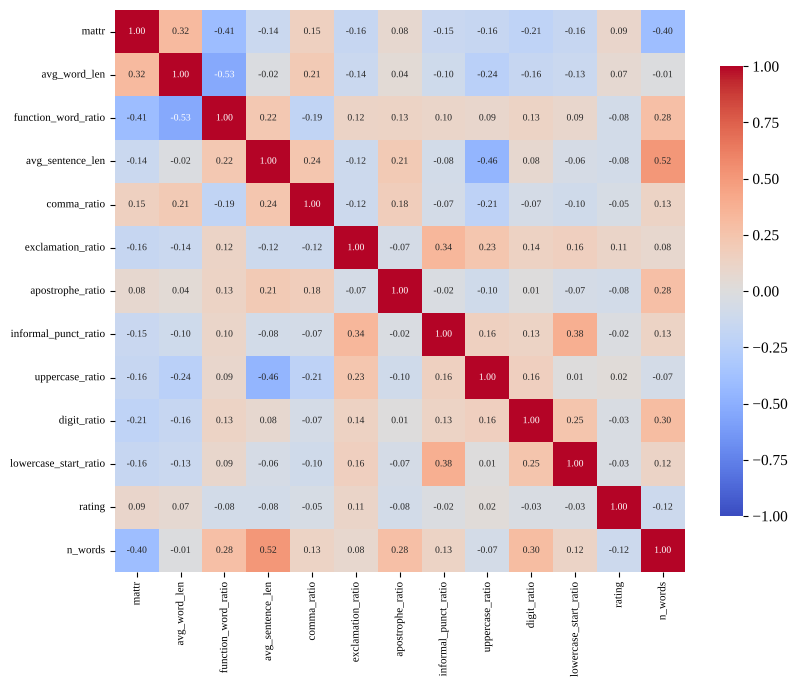

In [15]:
# 7d. Korelasi Spearman antarfitur
spearman = train[FEATS + ["rating", "n_words"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.8})
ax.tick_params(labelsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_korelasi_spearman.png"); plt.show()

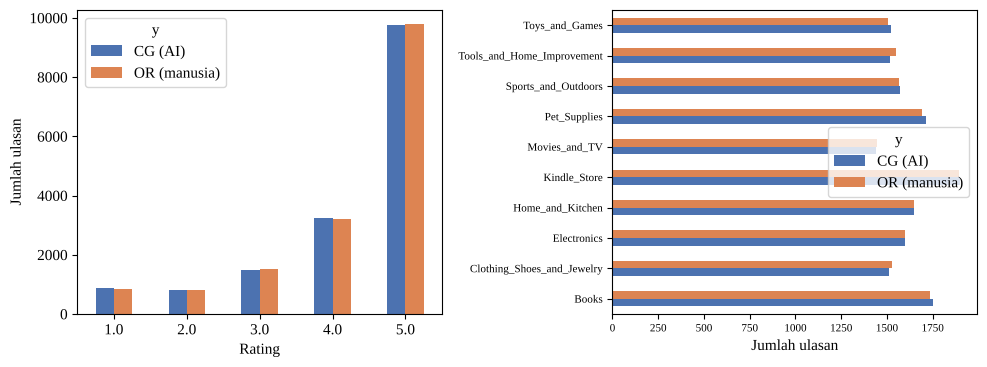

,category,rating,label,text_
18572,Sports_and_Outdoors_5,5.0,OR,My hydro flask insulation stopped working beca...
16036,Movies_and_TV_5,5.0,OR,Great movie. The 7.1 puts you into the movie l...
11340,Home_and_Kitchen_5,2.0,OR,Worked good at first until the grooves got clo...
5984,Clothing_Shoes_and_Jewelry_5,5.0,CG,Wore these almost daily for three months now a...
19936,Movies_and_TV_5,4.0,CG,I went into this mostly curious about Kaufman'...
10285,Sports_and_Outdoors_5,3.0,CG,"For the price, it's decent enough, but expect ..."


,AUROC,daya_pembeda
mattr,0.7646,0.2646
uppercase_ratio,0.2605,0.2395
comma_ratio,0.7231,0.2231
function_word_ratio,0.2946,0.2054
avg_word_len,0.7047,0.2047
apostrophe_ratio,0.6451,0.1451
digit_ratio,0.3825,0.1175
exclamation_ratio,0.3857,0.1143
lowercase_start_ratio,0.4079,0.0921
avg_sentence_len,0.5904,0.0904


In [16]:
# 7e. Contoh sampel per kelas dan 7f. temuan penting (AUROC satu fitur, rating, kategori)
samples = (train.groupby("y", group_keys=False)
           .apply(lambda d: d.sample(3, random_state=SEEDS[0]))[["category", "rating", "label", "text_"]])
single_auroc = pd.Series({f: sklearn.metrics.roc_auc_score(train.y, train[f])
                          for f in FEATS + ["rating"]}).rename("AUROC").to_frame()
single_auroc["daya_pembeda"] = (single_auroc["AUROC"] - 0.5).abs()
single_auroc = single_auroc.sort_values("daya_pembeda", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
pd.crosstab(train.rating, train.y.map(LABELS)).plot.bar(ax=axes[0], color=[COLORS[1], COLORS[0]][::-1], rot=0)
axes[0].set_xlabel("Rating"); axes[0].set_ylabel("Jumlah ulasan")
cat = pd.crosstab(train.category.str.replace("_5", ""), train.y.map(LABELS))
cat.plot.barh(ax=axes[1], color=[COLORS[1], COLORS[0]][::-1])
axes[1].set_xlabel("Jumlah ulasan"); axes[1].set_ylabel(""); axes[1].tick_params(labelsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_rating_kategori.png"); plt.show()
display(samples)
single_auroc.round(4)

## 8. Pemilihan fitur (data *training* saja)
Empat kriteria: (1) daya pembeda |AUROC − 0,5|; (2) pasangan dengan |ρ| > 0,9 hanya dipertahankan yang lebih kuat; (3) fitur dengan |ρ| > 0,9 terhadap jumlah kata dikeluarkan; (4) fitur artefak dikeluarkan.

In [17]:
selection_result = sel.select_features(train, FEATS)
SELECTED = selection_result["selected"]
print("Fitur terpilih:", len(SELECTED), SELECTED)
print("Tiga pasangan |rho| terbesar:", [(a, b, round(r, 4)) for a, b, r in selection_result["max_pair"]])
selection_result["table"].round(4)

Fitur terpilih: 11 ['mattr', 'avg_word_len', 'function_word_ratio', 'avg_sentence_len', 'comma_ratio', 'exclamation_ratio', 'apostrophe_ratio', 'informal_punct_ratio', 'uppercase_ratio', 'digit_ratio', 'lowercase_start_ratio']
Tiga pasangan |rho| terbesar: [('avg_word_len', 'function_word_ratio', np.float64(0.5345)), ('avg_sentence_len', 'uppercase_ratio', np.float64(0.4625)), ('mattr', 'function_word_ratio', np.float64(0.4089))]


,AUROC,Daya pembeda,rho_jumlah_kata,Keputusan
mattr,0.7646,0.2646,-0.4050,Dipertahankan
uppercase_ratio,0.2605,0.2395,-0.0747,Dipertahankan
comma_ratio,0.7231,0.2231,0.1312,Dipertahankan
function_word_ratio,0.2946,0.2054,0.2822,Dipertahankan
avg_word_len,0.7047,0.2047,-0.0133,Dipertahankan
apostrophe_ratio,0.6451,0.1451,0.2838,Dipertahankan
digit_ratio,0.3825,0.1175,0.3034,Dipertahankan
exclamation_ratio,0.3857,0.1143,0.0808,Dipertahankan
lowercase_start_ratio,0.4079,0.0921,0.1221,Dipertahankan
avg_sentence_len,0.5904,0.0904,0.5154,Dipertahankan


## 9. Penelusuran ulasan manusia sumber (*data leakage* pasangan)
Setiap ulasan AI dibuat dari satu ulasan manusia (`src_idx`). Pasangan ini ditelusuri dengan fungsi normalisasi yang sama dengan milik pembuat dataset.

In [18]:
sources = data_mod.trace_sources(test, train, val, DATA_DIR)
source_summary = sources["src_loc"].value_counts().rename("jumlah").to_frame()
source_summary["persen"] = (source_summary["jumlah"] / len(sources) * 100).round(2)
print("Kategori & rating sama dengan sumber:", sources["same_cat_rating"].mean())
source_summary

Kategori & rating sama dengan sumber: 1.0


,jumlah,persen
src_loc,,
train,2265,80.84
test,379,13.53
val,158,5.64


## 10. Penalaan arsitektur dan *learning rate*
Penalaan hanya dilakukan sekali pada skenario S1 dengan seed pertama (1998) berdasarkan AUROC data *validation*, lalu dikunci untuk seluruh skenario dan seed.

In [19]:
def xy(frame: pd.DataFrame, cols: list[str]) -> tuple[np.ndarray, np.ndarray]:
    return frame[cols].to_numpy("float32"), frame["y"].to_numpy("int32")

x_tr, y_tr = xy(train, SELECTED)
x_va, y_va = xy(val, SELECTED)
tuning_rows = []
for arch in ("M1", "M2"):
    for lr in (1e-3, 1e-4):
        res = mdl.train_model(arch, x_tr, y_tr, x_va, y_va, seed=SEEDS[0], lr=lr)
        tuning_rows.append({"arsitektur": arch, "learning_rate": lr,
                            "auroc_val": res.best_val_auroc, "epoch_terbaik": res.best_epoch,
                            "parameter_dilatih": int(sum(np.prod(w.shape) for w in res.model.trainable_weights))})
tuning = pd.DataFrame(tuning_rows).sort_values("auroc_val", ascending=False).reset_index(drop=True)
BEST_ARCH, BEST_LR = tuning.loc[0, "arsitektur"], float(tuning.loc[0, "learning_rate"])
print("Dikunci:", BEST_ARCH, BEST_LR)
tuning.round(4)

E0000 00:00:1793886324.124462     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886330.573058     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886336.864608     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886342.352950     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886348.894877     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886355.280594     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (13 outputs left out)

E0000 00:00:1793886436.608812     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886442.022273     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Dikunci: M2 0.001


,arsitektur,learning_rate,auroc_val,epoch_terbaik,parameter_dilatih
0,M2,0.0010,0.9555,12,3106
1,M1,0.0010,0.9548,8,3586
2,M1,0.0001,0.9531,20,3586
3,M2,0.0001,0.9527,19,3106


## 11. Pelatihan lima skenario × tiga seed
S0 = rating saja; S1 = fitur stilometrik terpilih; S2 = S1 + rating; S3 = S1 tanpa *dropout*/*batch normalization*, SGD *learning rate* tetap 0,01, tanpa *early stopping*; S4a/S4b = S1/S2 tanpa rasio koma (analisis sensitivitas terhadap normalisasi tanda pisah oleh pembuat dataset).

In [20]:
no_comma = [f for f in SELECTED if f != "comma_ratio"]
SCENARIOS = {
    "S0": {"cols": ["rating"], "regularized": True},
    "S1": {"cols": SELECTED, "regularized": True},
    "S2": {"cols": SELECTED + ["rating"], "regularized": True},
    "S3": {"cols": SELECTED, "regularized": False},
    "S4a": {"cols": no_comma, "regularized": True},
    "S4b": {"cols": no_comma + ["rating"], "regularized": True},
}
runs: dict[tuple[str, int], dict] = {}
t0 = time.time()
for name, cfg in SCENARIOS.items():
    for seed in SEEDS:
        xtr, ytr = xy(train, cfg["cols"]); xva, yva = xy(val, cfg["cols"])
        res = mdl.train_model(BEST_ARCH, xtr, ytr, xva, yva, seed=seed, lr=BEST_LR,
                              regularized=cfg["regularized"])
        pred = {split: res.model.predict(frame[cfg["cols"]].to_numpy("float32"),
                                         batch_size=1024, verbose=0)[:, 1]
                for split, frame in (("val", val), ("test", test), ("glm", glm), ("lfm", lfm))}
        t_star = ev.threshold_at_fpr(val.y.to_numpy(), pred["val"])
        runs[(name, seed)] = {"result": res, "pred": pred, "t_star": t_star}
        if name == "S1" and seed == SEEDS[0]:
            res.model.save(MODEL_DIR / "mlp_s1_seed1998.keras")
        print(f"{name} seed {seed}: epoch terbaik {res.best_epoch}, AUROC val {res.best_val_auroc:.4f}, t* {t_star:.4f}")
print(f"Total waktu pelatihan: {(time.time() - t0) / 60:.1f} menit")

E0000 00:00:1793886447.026960     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886452.698294     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


S0 seed 1998: epoch terbaik 1, AUROC val 0.5076, t* 0.5637


E0000 00:00:1793886458.191861     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


S0 seed 7: epoch terbaik 1, AUROC val 0.5076, t* 0.5227


E0000 00:00:1793886465.880696     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (81 outputs left out)

E0000 00:00:1793886849.522518     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886854.955461     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793886860.852213     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


S4b seed 42: epoch terbaik 14, AUROC val 0.9474, t* 0.9235
Total waktu pelatihan: 7.0 menit


## 12. Evaluasi
Metrik dihitung pada data *testing* untuk *threshold* t* dan 0,5, lalu dilaporkan sebagai rata-rata ± simpangan baku tiga seed.

In [21]:
y_te = test.y.to_numpy()
rows = []
for (name, seed), r in runs.items():
    for label, t in (("t*", r["t_star"]), ("0,5", 0.5)):
        m = ev.classification_metrics(y_te, r["pred"]["test"], t)
        m.update({"skenario": name, "seed": seed, "threshold": label, "t_value": t,
                  "fnr_glm": float((r["pred"]["glm"] < t).mean()),
                  "fnr_lfm": float((r["pred"]["lfm"] < t).mean()),
                  "best_epoch": r["result"].best_epoch,
                  "auroc_val": r["result"].best_val_auroc})
        rows.append(m)
metrics = pd.DataFrame(rows)
summary = (metrics.groupby(["skenario", "threshold"])
           [["accuracy", "precision", "recall", "f1", "fpr", "fnr", "auroc", "fnr_glm", "fnr_lfm"]]
           .agg(["mean", "std"]))
summary.round(4)

accuracy         precision          recall              f1  \
                       mean     std      mean     std    mean     std    mean   
skenario threshold                                                              
S0       0,5         0.4976  0.0045    0.4880  0.0016  0.2866  0.1589  0.3407   
         t*          0.5049  0.0000    0.0000  0.0000  0.0000  0.0000  0.0000   
S1       0,5         0.8972  0.0027    0.8890  0.0100  0.9055  0.0070  0.8971   
         t*          0.7051  0.0022    0.9821  0.0010  0.4118  0.0041  0.5803   
S2       0,5         0.8989  0.0015    0.9013  0.0042  0.8938  0.0085  0.8975   
         t*          0.6989  0.0094    0.9833  0.0016  0.3986  0.0199  0.5671   
S3       0,5         0.8963  0.0026    0.8825  0.0132  0.9122  0.0124  0.8970   
         t*          0.7062  0.0156    0.9806  0.0009  0.4147  0.0322  0.5824   
S4a      0,5         0.8829  0.0007    0.8740  0.0011  0.8921  0.0014  0.8830   
         t*          0.6710  0.0046    0.9849  0.0019  0.3406  0.0097  0.5061   
S4b      0,5         0.8845  0.0015    0.8791  0.0122  0.8892  0.0196  0.8839   
         t*          0.6700  0.0061    0.9851  0.0010  0.3384  0.0129  0.5037   

                               fpr             fnr           auroc          \
                       std    mean     std    mean     std    mean     std   
skenario threshold                                                           
S0       0,5        0.1475  0.2954  0.1646  0.7134  0.1589  0.4940  0.0006   
         t*         0.0000  0.0000  0.0000  1.0000  0.0000  0.4940  0.0006   
S1       0,5        0.0018  0.1110  0.0122  0.0945  0.0070  0.9605  0.0008   
         t*         0.0043  0.0073  0.0003  0.5882  0.0041  0.9605  0.0008   
S2       0,5        0.0023  0.0960  0.0054  0.1062  0.0085  0.9610  0.0003   
         t*         0.0199  0.0066  0.0009  0.6014  0.0199  0.9610  0.0003   
S3       0,5        0.0014  0.1193  0.0165  0.0878  0.0124  0.9594  0.0003   
         t*         0.0314  0.0080  0.0007  0.5853  0.0322  0.9594  0.0003   
S4a      0,5        0.0007  0.1261  0.0013  0.1079  0.0014  0.9529  0.0005   
         t*         0.0106  0.0051  0.0007  0.6594  0.0097  0.9529  0.0005   
S4b      0,5        0.0036  0.1202  0.0162  0.1108  0.0196  0.9534  0.0013   
         t*         0.0141  0.0050  0.0005  0.6616  0.0129  0.9534  0.0013   

                   fnr_glm         fnr_lfm          
                      mean     std    mean     std  
skenario threshold                                  
S0       0,5        0.7077  0.1727  0.7173  0.1626  
         t*         1.0000  0.0000  1.0000  0.0000  
S1       0,5        0.2670  0.0135  0.4540  0.0139  
         t*         0.8166  0.0065  0.8417  0.0091  
S2       0,5        0.3040  0.0208  0.4904  0.0318  
         t*         0.8328  0.0127  0.8619  0.0080  
S3       0,5        0.2286  0.0346  0.4060  0.0349  
         t*         0.7920  0.0202  0.8305  0.0206  
S4a      0,5        0.2049  0.0146  0.4636  0.0280  
         t*         0.7791  0.0128  0.8710  0.0133  
S4b      0,5        0.2063  0.0273  0.4447  0.0354  
         t*         0.7814  0.0150  0.8812  0.0053

In [22]:
# Uji McNemar mid-p pada data testing (threshold t* masing-masing model)
def correct(name: str, seed: int) -> np.ndarray:
    r = runs[(name, seed)]
    return (r["pred"]["test"] >= r["t_star"]).astype(int) == y_te

COMPARISONS = [("S1", "S0"), ("S2", "S1"), ("S3", "S1"), ("S4a", "S1"), ("S4b", "S2")]
mc_rows = []
for b, a in COMPARISONS:
    for seed in SEEDS:
        res = ev.mcnemar_midp(correct(a, seed), correct(b, seed))
        better = b if res["n01"] > res["n10"] else a
        verdict = f"{better} lebih baik" if res["p_mid"] <= 0.05 else "Tidak berbeda"
        mc_rows.append({"perbandingan": f"{b} terhadap {a}", "seed": seed, **res, "kesimpulan": verdict})
mcnemar = pd.DataFrame(mc_rows)
consistency = mcnemar.groupby("perbandingan").apply(
    lambda d: pd.Series({"p_maks": d.p_mid.max(),
                         "konsisten": bool(d.p_mid.max() <= 0.05 and d.kesimpulan.nunique() == 1)}))
display(mcnemar)
consistency

,perbandingan,seed,n01,n10,n,p_mid,kesimpulan
0,S1 terhadap S0,1998,1155,21,1176,0.000000e+00,S1 lebih baik
1,S1 terhadap S0,7,1165,20,1185,0.000000e+00,S1 lebih baik
2,S1 terhadap S0,42,1142,22,1164,0.000000e+00,S1 lebih baik
3,S2 terhadap S1,1998,42,128,170,1.740898e-11,S1 lebih baik
4,S2 terhadap S1,7,50,41,91,3.481413e-01,Tidak berbeda
5,S2 terhadap S1,42,67,95,162,2.798897e-02,S1 lebih baik
6,S3 terhadap S1,1998,158,51,209,4.108486e-14,S3 lebih baik
7,S3 terhadap S1,7,74,136,210,1.721693e-05,S1 lebih baik
8,S3 terhadap S1,42,100,127,227,7.352483e-02,Tidak berbeda
9,S4a terhadap S1,1998,119,294,413,2.413474e-18,S1 lebih baik


,p_maks,konsisten
perbandingan,,
S1 terhadap S0,0.000000e+00,True
S2 terhadap S1,3.481413e-01,False
S3 terhadap S1,7.352483e-02,False
S4a terhadap S1,2.413474e-18,True
S4b terhadap S2,6.255796e-05,True


In [23]:
# Analisis lanjutan pada model acuan S1 seed 1998 (ambang t*)
ref = runs[("S1", SEEDS[0])]
T_REF = ref["t_star"]
test_eval = test.assign(p=ref["pred"]["test"], pred=(ref["pred"]["test"] >= T_REF).astype(int))
bins = [0, Q1, Q2, Q3, np.inf]
group_names = [f"K1 (<= {Q1} kata)", f"K2 ({Q1 + 1}-{Q2} kata)", f"K3 ({Q2 + 1}-{Q3} kata)", f"K4 (> {Q3} kata)"]
test_eval["kelompok"] = pd.cut(test_eval.n_words, bins=bins, labels=group_names)

def group_metrics(frame: pd.DataFrame) -> pd.Series:
    m = ev.classification_metrics(frame.y.to_numpy(), frame.p.to_numpy(), T_REF)
    return pd.Series({"n": len(frame), "FPR": m["fpr"], "FNR": m["fnr"], "AUROC": m["auroc"]})

by_length = test_eval.groupby("kelompok", observed=True).apply(group_metrics)
within = test_eval[test_eval.n_words <= L_MAX]
m_within = ev.classification_metrics(within.y.to_numpy(), within.p.to_numpy(), T_REF)
over_lmax = test_eval[test_eval.n_words > L_MAX]
by_category = test_eval.groupby("category").apply(group_metrics)
by_generator = pd.Series({"DeepSeek-v4-pro": float((test_eval.loc[test_eval.y == 1, "p"] < T_REF).mean()),
                          "GLM-5.2": float((ref["pred"]["glm"] < T_REF).mean()),
                          "LFM2.5-1.2B": float((ref["pred"]["lfm"] < T_REF).mean())}, name="FNR")
src_eval = sources.merge(test_eval[["text_", "pred"]], on="text_", how="left")
by_source = src_eval.groupby("src_loc").agg(ulasan_ai=("pred", "size"),
                                            lolos=("pred", lambda s: int((s == 0).sum())))
by_source["FNR"] = by_source["lolos"] / by_source["ulasan_ai"]
fp_examples = test_eval[(test_eval.y == 0) & (test_eval.pred == 1)].nlargest(3, "p")
fn_examples = test_eval[(test_eval.y == 1) & (test_eval.pred == 0)].nsmallest(3, "p")
print("Ulasan <= L_maks:", len(within), "AUROC", round(m_within["auroc"], 4),
      "| Ulasan > L_maks (manusia):", len(over_lmax), "FPR", round(float(over_lmax.pred.mean()), 4))
display(by_length.round(4), by_category.round(4), by_generator.round(4), by_source.round(4))
pd.concat([fp_examples, fn_examples])[["label", "n_words", "p", "text_"]]

Ulasan <= L_maks: 5221 AUROC 0.9574 | Ulasan > L_maks (manusia): 439 FPR 0.0046


,n,FPR,FNR,AUROC
kelompok,,,,
K1 (<= 22 kata),1461.0,0.0103,0.7535,0.9141
K2 (23-42 kata),1395.0,0.0092,0.6956,0.9436
K3 (43-91 kata),1436.0,0.0055,0.4958,0.9776
K4 (> 91 kata),1368.0,0.0043,0.3905,0.9903


,n,FPR,FNR,AUROC
category,,,,
Books_5,631.0,0.0000,0.5513,0.9691
Clothing_Shoes_and_Jewelry_5,558.0,0.0071,0.6764,0.9541
Electronics_5,543.0,0.0036,0.5602,0.9571
Home_and_Kitchen_5,536.0,0.0148,0.5414,0.9596
Kindle_Store_5,669.0,0.0030,0.5740,0.9610
Movies_and_TV_5,483.0,0.0042,0.5802,0.9627
Pet_Supplies_5,586.0,0.0067,0.5571,0.9725
Sports_and_Outdoors_5,570.0,0.0133,0.5353,0.9553
Tools_and_Home_Improvement_5,552.0,0.0112,0.6702,0.9582


DeepSeek-v4-pro    0.5878
GLM-5.2            0.8092
LFM2.5-1.2B        0.8312
Name: FNR, dtype: float64

,ulasan_ai,lolos,FNR
src_loc,,,
test,379,221,0.5831
train,2265,1326,0.5854
val,158,100,0.6329


,label,n_words,p,text_
671,OR,13,0.981264,"In today's stressful world and environment, we..."
797,OR,16,0.960021,"Soft fluffy, unlike a lot of stuffed animals o..."
398,OR,27,0.959513,I love that the kids can create sandwiches and...
1860,CG,7,0.007903,Just as comfy as I'd hoped for.
1915,CG,12,0.020469,"Perfect for tiny pups under 10 lbs, my chihuah..."
1922,CG,26,0.021310,What a perfect wrap-up to a series I couldn't ...


## 13. Grafik pelatihan dan evaluasi

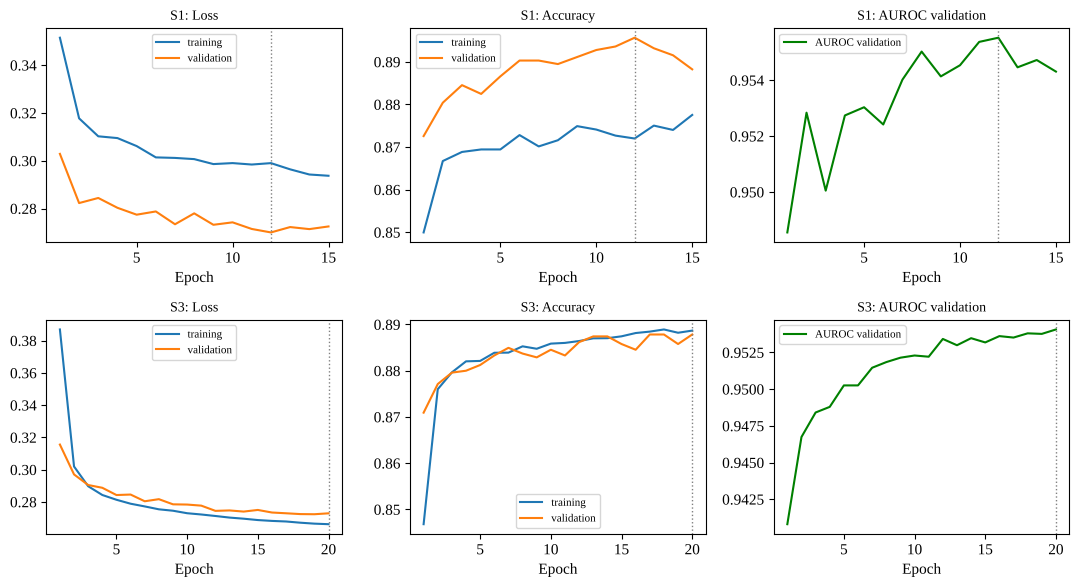

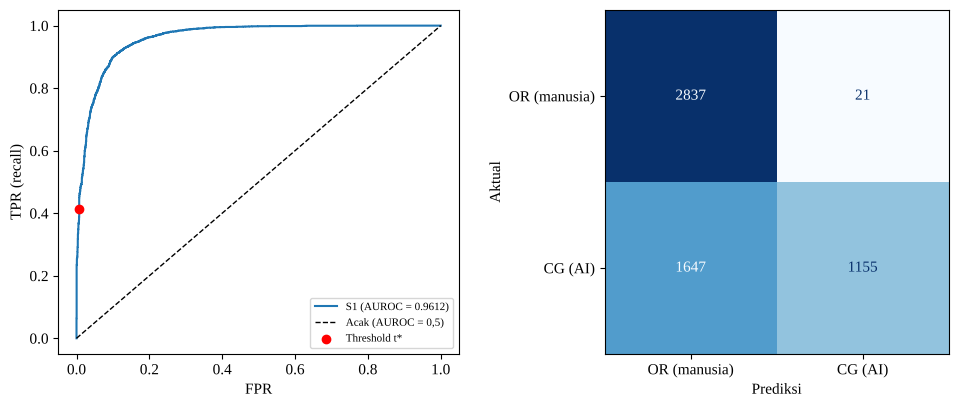

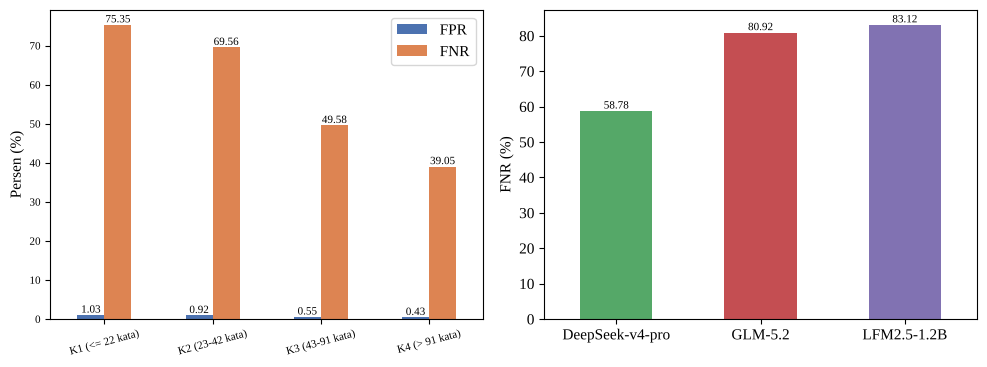

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for row, name in enumerate(("S1", "S3")):
    h = runs[(name, SEEDS[0])]["result"].history
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[row, 0].plot(ep, h["loss"], label="training"); axes[row, 0].plot(ep, h["val_loss"], label="validation")
    axes[row, 1].plot(ep, h["accuracy"], label="training"); axes[row, 1].plot(ep, h["val_accuracy"], label="validation")
    axes[row, 2].plot(ep, h["val_auroc"], color="green", label="AUROC validation")
    best = runs[(name, SEEDS[0])]["result"].best_epoch
    for ax, ttl in zip(axes[row], ("Loss", "Accuracy", "AUROC validation")):
        ax.axvline(best, color="grey", ls=":", lw=1); ax.set_title(f"{name}: {ttl}", fontsize=10)
        ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "grafik_loss_akurasi.png"); plt.show()

from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
fpr_c, tpr_c, _ = roc_curve(y_te, ref["pred"]["test"])
m_ref = ev.classification_metrics(y_te, ref["pred"]["test"], T_REF)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].plot(fpr_c, tpr_c, label=f"S1 (AUROC = {m_ref['auroc']:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Acak (AUROC = 0,5)")
axes[0].scatter([m_ref["fpr"]], [1 - m_ref["fnr"]], color="red", zorder=3, label="Threshold t*")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR (recall)"); axes[0].legend(fontsize=8)
cm = np.array([[m_ref["TN"], m_ref["FP"]], [m_ref["FN"], m_ref["TP"]]])
ConfusionMatrixDisplay(cm, display_labels=["OR (manusia)", "CG (AI)"]).plot(ax=axes[1], colorbar=False, cmap="Blues", values_format="d")
axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Aktual")
fig.tight_layout(); fig.savefig(FIG_DIR / "roc_confusion_matrix.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
by_length[["FPR", "FNR"]].mul(100).plot.bar(ax=axes[0], rot=15, color=["#4C72B0", "#DD8452"])
axes[0].set_ylabel("Persen (%)"); axes[0].set_xlabel(""); axes[0].tick_params(labelsize=8)
by_generator.mul(100).plot.bar(ax=axes[1], rot=0, color=["#55A868", "#C44E52", "#8172B2"])
axes[1].set_ylabel("FNR (%)")
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "analisis_panjang_generator.png"); plt.show()

## 14. Bukti dampak dua fitur unik
**Fitur unik 1** menggantikan *threshold* 0,5 dengan t* berbasis FPR *validation* ≤ 1%. **Fitur unik 2** memeriksa masukan sebelum prediksi (kosong, bukan bahasa Inggris, panjang di luar kisaran Q1 < N ≤ L_maks).

In [25]:
feature1 = summary.loc[(["S1", "S2"], slice(None)), [("fpr", "mean"), ("fpr", "std"), ("fnr", "mean"),
                                                     ("fnr", "std"), ("accuracy", "mean"), ("accuracy", "std")]]

def english_text(n: int) -> str:
    base = ("this blender works well and the lid feels solid but the motor is a bit loud "
            "when i crush ice for smoothies in the morning so i use it later in the day").split()
    words = (base * (n // len(base) + 1))[:n]
    return " ".join(words).capitalize() + "."

def predict_one(text: str) -> dict:
    check = inf.check_input(text, Q1, L_MAX)
    if check.status != "ok":
        return {"status": check.status, "pesan": check.message}
    x = np.array([[sty.extract_features(text)[f] for f in SELECTED]], dtype="float32")
    p = float(ref["result"].model.predict(x, verbose=0)[0, 1])
    return {"status": "ok", "n_kata": check.n_words, "p": round(p, 4),
            "kategori": "Terindikasi ditulis AI" if p >= T_REF else "Tidak terindikasi ditulis AI",
            "peringatan": len(check.warnings)}

cases = [("Teks bahasa Inggris Q1 + 1 kata", english_text(Q1 + 1)),
         ("Teks bahasa Inggris L_maks kata", english_text(L_MAX)),
         ("Teks kosong", "   "),
         ("Teks bahasa Indonesia", "Produk ini sangat bagus, pengirimannya cepat dan kemasannya rapi sekali."),
         ("Teks bahasa Inggris Q1 kata", english_text(Q1)),
         ("Teks bahasa Inggris L_maks + 1 kata", english_text(L_MAX + 1)),
         ("Teks no. 1 diperiksa ulang", english_text(Q1 + 1))]
blackbox = pd.DataFrame([{"masukan": c, **predict_one(t)} for c, t in cases])
display(feature1.round(4))
blackbox

E0000 00:00:1793886867.082119     772 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


fpr             fnr         accuracy        
                      mean     std    mean     std     mean     std
skenario threshold                                                 
S1       0,5        0.1110  0.0122  0.0945  0.0070   0.8972  0.0027
         t*         0.0073  0.0003  0.5882  0.0041   0.7051  0.0022
S2       0,5        0.0960  0.0054  0.1062  0.0085   0.8989  0.0015
         t*         0.0066  0.0009  0.6014  0.0199   0.6989  0.0094

,masukan,status,n_kata,p,kategori,peringatan,pesan
0,Teks bahasa Inggris Q1 + 1 kata,ok,23.0,0.3648,Tidak terindikasi ditulis AI,0.0,NaN
1,Teks bahasa Inggris L_maks kata,ok,136.0,0.0000,Tidak terindikasi ditulis AI,0.0,NaN
2,Teks kosong,kosong,NaN,NaN,NaN,NaN,Teks ulasan wajib diisi.
3,Teks bahasa Indonesia,bukan_inggris,NaN,NaN,NaN,NaN,Hanya teks ulasan berbahasa Inggris yang diduk...
4,Teks bahasa Inggris Q1 kata,ok,22.0,0.4524,Tidak terindikasi ditulis AI,1.0,NaN
5,Teks bahasa Inggris L_maks + 1 kata,ok,137.0,0.0000,Tidak terindikasi ditulis AI,1.0,NaN
6,Teks no. 1 diperiksa ulang,ok,23.0,0.3648,Tidak terindikasi ditulis AI,0.0,NaN


## 15. Penyimpanan hasil
Seluruh angka yang dikutip di laporan disimpan ke `outputs/results.json` agar laporan dan kode konsisten.

In [26]:
def fmt_df(df: pd.DataFrame) -> dict:
    return json.loads(df.to_json(orient="split", double_precision=6))

params = ref["result"].model.count_params()
trainable = int(sum(np.prod(w.shape) for w in ref["result"].model.trainable_weights))
results = {
    "versions": VERSIONS, "seeds": SEEDS, "split_sizes": fmt_df(split_sizes),
    "clean_report": fmt_df(clean_report), "wc_stats": fmt_df(wc_stats),
    "L_MAX": L_MAX, "Q": [Q1, Q2, Q3], "feat_means": fmt_df(feat_means),
    "single_auroc": fmt_df(single_auroc), "samples": fmt_df(samples),
    "selection": fmt_df(selection_result["table"]), "selected": SELECTED,
    "max_pair": selection_result["max_pair"], "source_summary": fmt_df(source_summary),
    "same_cat_rating": float(sources["same_cat_rating"].mean()),
    "tuning": fmt_df(tuning), "best_arch": BEST_ARCH, "best_lr": BEST_LR,
    "metrics": fmt_df(metrics), "mcnemar": fmt_df(mcnemar),
    "consistency": fmt_df(consistency.astype({"konsisten": int})),
    "t_ref": T_REF, "ref_metrics": {k: float(v) for k, v in m_ref.items()},
    "by_length": fmt_df(by_length), "within_lmax": {"n": len(within), "auroc": m_within["auroc"]},
    "over_lmax": {"n": len(over_lmax), "fpr": float(over_lmax.pred.mean())},
    "by_category": fmt_df(by_category), "by_generator": by_generator.to_dict(),
    "by_source": fmt_df(by_source),
    "errors": fmt_df(pd.concat([fp_examples, fn_examples])[["label", "n_words", "p", "text_"]]),
    "blackbox": fmt_df(blackbox), "params_total": int(params), "params_trainable": trainable,
    "summary_text": [],
    "history_S1": runs[("S1", SEEDS[0])]["result"].history,
    "history_S3": runs[("S3", SEEDS[0])]["result"].history,
    "n_glm": len(glm), "n_lfm": len(lfm),
}
ref["result"].model.summary(print_fn=lambda line, *args, **kw: results["summary_text"].append(line))
(OUT_DIR / "results.json").write_text(json.dumps(results, indent=1, default=float))
print("Tersimpan:", OUT_DIR / "results.json", "| parameter total", params, "dilatih", trainable)

Tersimpan: /home/claude/build/Kode Program UTS/outputs/results.json | parameter total 3321 dilatih 3106


## 16. Fitur unik 4: kompresi model ke TensorFlow Lite
Model S1 seed 1998 dikonversi ke TFLite dengan optimasi *float16*, lalu dibandingkan dengan model Keras pada seluruh data *testing*.

In [27]:
from ai_edge_litert.interpreter import Interpreter

keras_model = ref["result"].model
converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_bytes = converter.convert()
APP_DIR = ROOT / "app"
APP_DIR.mkdir(exist_ok=True)
(APP_DIR / "mlp_s1.tflite").write_bytes(tflite_bytes)

interp = Interpreter(model_content=tflite_bytes)
interp.allocate_tensors()
i_in, i_out = interp.get_input_details()[0]["index"], interp.get_output_details()[0]["index"]
x_test = test[SELECTED].to_numpy("float32")
p_lite = np.empty(len(x_test), dtype="float64")
t0 = time.perf_counter()
for i, row in enumerate(x_test):
    interp.set_tensor(i_in, row[None, :]); interp.invoke()
    p_lite[i] = interp.get_tensor(i_out)[0, 1]
lite_ms = (time.perf_counter() - t0) / len(x_test) * 1000
t0 = time.perf_counter()
for row in x_test[:200]:
    keras_model(row[None, :], training=False)
keras_ms = (time.perf_counter() - t0) / 200 * 1000
p_keras = ref["pred"]["test"]
keras_kb = (MODEL_DIR / "mlp_s1_seed1998.keras").stat().st_size / 1024
lite_kb = len(tflite_bytes) / 1024
tflite_cmp = pd.DataFrame({
    "Keras": [keras_kb, keras_ms, sklearn.metrics.roc_auc_score(y_te, p_keras), np.nan, np.nan],
    "TFLite": [lite_kb, lite_ms, sklearn.metrics.roc_auc_score(y_te, p_lite),
               float(((p_lite >= T_REF) == (p_keras >= T_REF)).mean()), float(np.abs(p_lite - p_keras).max())]},
    index=["ukuran_kb", "ms_per_ulasan", "auroc_test", "keputusan_sama", "selisih_p_maks"])
tflite_cmp.round(6)

INFO:tensorflow:Assets written to: /tmp/tmpf_yyh_9t/assets


INFO:tensorflow:Assets written to: /tmp/tmpf_yyh_9t/assets


Saved artifact at '/tmp/tmpf_yyh_9t'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 11), dtype=tf.float32, name='fitur')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140402695011408: TensorSpec(shape=(1, 11), dtype=tf.float32, name=None)
  140402695008720: TensorSpec(shape=(1, 11), dtype=tf.float32, name=None)
  140402695008912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695009104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695009680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695008336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695004688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695009872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695010256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695002960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140402695010448: Tenso

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


,Keras,TFLite
ukuran_kb,89.840820,9.710938
ms_per_ulasan,4.449821,0.002730
auroc_test,0.961209,0.961202
keputusan_sama,NaN,0.999470
selisih_p_maks,NaN,0.002894


## 17. Artefak aplikasi website
`config.json` menyimpan daftar fitur, t*, Q1, L_maks, dan FPR/FNR tiap kelompok panjang (fitur unik 3). Modul `stylometry.py` dan `inference.py` disalin dari `src/`, sehingga aplikasi memakai kode ekstraksi yang sama dengan pelatihan.

In [28]:
import shutil
for name in ("stylometry.py", "inference.py"):
    shutil.copy(SRC_DIR / name, APP_DIR / name)
groups = []
edges = [(1, Q1), (Q1 + 1, Q2), (Q2 + 1, Q3), (Q3 + 1, 10**6)]
for (lo, hi), gname in zip(edges, group_names):
    row = by_length.loc[gname]
    groups.append({"name": gname, "min": lo, "max": hi,
                   "fpr": None if pd.isna(row.FPR) else float(row.FPR),
                   "fnr": None if pd.isna(row.FNR) else float(row.FNR)})
config = {"model": "MLP " + BEST_ARCH + " skenario S1 seed 1998 (TFLite float16)",
          "features": SELECTED, "t_star": T_REF, "q1": Q1, "l_max": L_MAX,
          "length_groups": groups}
(APP_DIR / "config.json").write_text(json.dumps(config, indent=2))
config

{'model': 'MLP M2 skenario S1 seed 1998 (TFLite float16)',
 'features': ['mattr',
  'avg_word_len',
  'function_word_ratio',
  'avg_sentence_len',
  'comma_ratio',
  'exclamation_ratio',
  'apostrophe_ratio',
  'informal_punct_ratio',
  'uppercase_ratio',
  'digit_ratio',
  'lowercase_start_ratio'],
 't_star': 0.9235208034515381,
 'q1': 22,
 'l_max': 136,
 'length_groups': [{'name': 'K1 (<= 22 kata)',
   'min': 1,
   'max': 22,
   'fpr': 0.01032448377581121,
   'fnr': 0.7535121328224776},
  {'name': 'K2 (23-42 kata)',
   'min': 23,
   'max': 42,
   'fpr': 0.009198423127463863,
   'fnr': 0.695583596214511},
  {'name': 'K3 (43-91 kata)',
   'min': 43,
   'max': 91,
   'fpr': 0.00554016620498615,
   'fnr': 0.4957983193277311},
  {'name': 'K4 (> 91 kata)',
   'min': 92,
   'max': 1000000,
   'fpr': 0.00430416068866571,
   'fnr': 0.39046199701937406}]}

In [29]:
%%writefile app/app.py
"""Aplikasi web Streamlit: deteksi ulasan produk hasil generatif AI (MLP + fitur stilometrik).

Model yang dipasang adalah model S1 seed 1998 yang dievaluasi di laporan,
dikompresi ke TensorFlow Lite (float16). Ekstraksi fitur memakai modul
stylometry.py yang sama persis dengan saat pelatihan.

Menjalankan secara lokal : streamlit run app.py
Deployment               : Streamlit Community Cloud, main file path app/app.py
"""
from __future__ import annotations

import json
from pathlib import Path
from typing import Dict, List

import numpy as np
import streamlit as st

from inference import check_input
from stylometry import clean_text, count_words, extract_features

try:  # LiteRT (pengganti tflite_runtime); TensorFlow tidak diperlukan
    from ai_edge_litert.interpreter import Interpreter
except ImportError:  # pragma: no cover - cadangan bila LiteRT tidak tersedia
    from tensorflow.lite import Interpreter  # type: ignore

HERE = Path(__file__).resolve().parent
DISCLAIMER = ("Hasil ini hanya dugaan asal penulisan, bukan kepastian dan bukan "
              "penilaian atas niat penulis.")
EXAMPLES: List[str] = [
    "I bought this for my daughter and she loves it. The colors are bright, the material "
    "feels sturdy, and it survived a week of daily use without any scratches. Shipping "
    "was quick too.",
    "got it yesterday... honestly not sure yet!! the strap broke after 2 days but the "
    "seller replaced it fast so i guess its ok",
    "Produk ini sangat bagus dan pengirimannya cepat sekali.",
]


@st.cache_resource
def load_model():
    """Muat config.json dan interpreter TFLite sekali saja untuk seluruh sesi."""
    config = json.loads((HERE / "config.json").read_text(encoding="utf-8"))
    interpreter = Interpreter(model_path=str(HERE / "mlp_s1.tflite"))
    interpreter.allocate_tensors()
    return config, interpreter


CONFIG, INTERPRETER = load_model()
_IN = INTERPRETER.get_input_details()[0]["index"]
_OUT = INTERPRETER.get_output_details()[0]["index"]
Q1, L_MAX, T_STAR = CONFIG["q1"], CONFIG["l_max"], CONFIG["t_star"]


def predict_proba(text: str) -> float:
    """Peluang ulasan ditulis AI menurut model TFLite."""
    feats = extract_features(text)
    x = np.array([[feats[name] for name in CONFIG["features"]]], dtype=np.float32)
    INTERPRETER.set_tensor(_IN, x)
    INTERPRETER.invoke()
    return float(INTERPRETER.get_tensor(_OUT)[0, 1])


def reliability_group(n_words: int) -> Dict:
    """Fitur unik 3: pilih FPR/FNR data testing sesuai kelompok panjang teks."""
    for group in CONFIG["length_groups"]:
        if group["min"] <= n_words <= group["max"]:
            return group
    return CONFIG["length_groups"][-1]


def pct(value) -> str:
    return "-" if value is None else f"{value * 100:.2f}%".replace(".", ",")


def word_info(text: str) -> str:
    return (f"Jumlah kata: **{count_words(clean_text(text))}** · Panjang yang disarankan: "
            f"**{Q1 + 1} sampai {L_MAX} kata**")


def analyze(text: str) -> Dict:
    """Jalankan pemeriksaan masukan (fitur unik 2), prediksi, dan susun hasil."""
    check = check_input(text, Q1, L_MAX)
    if check.status != "ok":
        return {"status": "invalid", "message": check.message}
    p = predict_proba(clean_text(text))
    group = reliability_group(check.n_words)
    return {"status": "ok", "p": p, "is_ai": p >= T_STAR, "group": group,
            "warnings": check.warnings}


# ----------------------------- state & callback -----------------------------
if "text" not in st.session_state:
    st.session_state.text = ""
    st.session_state.result = None


def on_check() -> None:
    st.session_state.result = analyze(st.session_state.text)


def on_clear() -> None:
    st.session_state.text = ""
    st.session_state.result = None


def on_example(idx: int) -> None:
    st.session_state.text = EXAMPLES[idx]


# ---------------------------------- layout ----------------------------------
st.set_page_config(page_title="Deteksi Ulasan Produk Buatan AI", page_icon="🔎",
                   layout="wide")
st.title("🔎 Deteksi Ulasan Produk Buatan AI")
st.caption("🔒 Teks dan hasil tidak disimpan")

left, right = st.columns(2, gap="large")
with left:
    st.text_area("Teks Ulasan", key="text", height=230,
                 placeholder="Tempel teks ulasan berbahasa Inggris di sini")
    st.markdown(word_info(st.session_state.text))
    b1, b2 = st.columns(2)
    b1.button("Bersihkan", on_click=on_clear, width="stretch")
    b2.button("Periksa Ulasan", type="primary", on_click=on_check,
              width="stretch")
    st.markdown("**Contoh masukan siap coba**")
    for i, example in enumerate(EXAMPLES):
        label = example if len(example) <= 60 else example[:57] + "..."
        st.button(label, key=f"ex{i}", on_click=on_example, args=(i,))

with right:
    st.subheader("Laporan Hasil Deteksi")
    res = st.session_state.result
    if res is None:
        st.markdown("*Hasil deteksi akan tampil di sini setelah tombol "
                    "Periksa Ulasan ditekan.*")
    elif res["status"] == "invalid":
        st.warning(res["message"], icon="⚠️")
    else:
        for w in res["warnings"]:
            st.warning(w, icon="⚠️")
        category = ("Terindikasi ditulis AI" if res["is_ai"]
                    else "Tidak terindikasi ditulis AI")
        st.markdown(f"#### Kategori dugaan: {category}")
        group = res["group"]
        st.markdown(f"**Keandalan model pada data uji ({group['name']}):**")
        st.markdown(
            "| Ulasan manusia keliru dideteksi sebagai AI (FPR) | "
            "Ulasan AI gagal terdeteksi (FNR) |\n|:---:|:---:|\n"
            f"| {pct(group['fpr'])} | {pct(group['fnr'])} |")
        p_txt = f"{res['p']:.4f}".replace(".", ",")
        t_txt = f"{T_STAR:.4f}".replace(".", ",")
        st.markdown(f"Peluang ditulis AI menurut model: {p_txt} (threshold t* = {t_txt})")
        st.info(DISCLAIMER)

Writing app/app.py


## 18. Uji *black-box* fungsi aplikasi
Fungsi `analyze` pada `app.py` diuji dengan skenario pengujian dari rancangan (Tabel 3.19 skripsi) tanpa membuka antarmuka.

In [30]:
sys.path.insert(0, str(APP_DIR))
import app as web_app  # di luar `streamlit run`, Streamlit berjalan dalam bare mode tanpa antarmuka
importlib.reload(web_app)
app_cases = cases + [("Teks Inggris contoh aplikasi", web_app.EXAMPLES[0])]
app_rows = []
for desc, text in app_cases:
    res = web_app.analyze(text)
    if res["status"] == "ok":
        label = "Terindikasi ditulis AI" if res["is_ai"] else "Tidak terindikasi ditulis AI"
        pesan, n_warn = "### Kategori dugaan: " + label, len(res["warnings"])
    else:
        pesan, n_warn = "⚠️ " + res["message"], 0
    app_rows.append({"masukan": desc, "n_kata": sty.count_words(sty.clean_text(text)),
                     "pesan/kategori": pesan, "peringatan": n_warn})
app_blackbox = pd.DataFrame(app_rows)
same = web_app.analyze(app_cases[0][1]) == web_app.analyze(app_cases[-2][1])
results.update({"tflite": fmt_df(tflite_cmp), "config": config,
                "app_blackbox": fmt_df(app_blackbox), "app_consistent": bool(same)})
(OUT_DIR / "results.json").write_text(json.dumps(results, indent=1, default=float))
print("Teks sama memberi hasil sama:", same)
app_blackbox

Teks sama memberi hasil sama: True


,masukan,n_kata,pesan/kategori,peringatan
0,Teks bahasa Inggris Q1 + 1 kata,23,### Kategori dugaan: Tidak terindikasi ditulis AI,0
1,Teks bahasa Inggris L_maks kata,136,### Kategori dugaan: Tidak terindikasi ditulis AI,0
2,Teks kosong,0,⚠️ Teks ulasan wajib diisi.,0
3,Teks bahasa Indonesia,10,⚠️ Hanya teks ulasan berbahasa Inggris yang di...,0
4,Teks bahasa Inggris Q1 kata,22,### Kategori dugaan: Tidak terindikasi ditulis AI,1
5,Teks bahasa Inggris L_maks + 1 kata,137,### Kategori dugaan: Tidak terindikasi ditulis AI,1
6,Teks no. 1 diperiksa ulang,23,### Kategori dugaan: Tidak terindikasi ditulis AI,0
7,Teks Inggris contoh aplikasi,33,### Kategori dugaan: Tidak terindikasi ditulis AI,0
